# [TGCA-COAD](https://portal.gdc.cancer.gov/projects/TCGA-COAD)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-06-29
> - Modified: 2023-09-12

# 1. Experimental Design

> The Cancer Genome Atlas Colon Adenocarcinoma Collection
> - Assembly: hg38
> - Annotation: Genecode Release 36 (GRCh38.p13), gencode.v36.annotation.gtf
> - The Cancer Genome Atlas Network. Comprehensive molecular characterization of human colon and rectal cancer. Nature 487, 330–337 (2012). https://doi.org/10.1038/nature11252.

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 2. Import Data

In [2]:
# suppressPackageStartupMessages(library(TCGAbiolinks))

# TCGA_PROJECT <- "TCGA-COAD"
# DATA_DIR <- "~/dataset_1/database/GDCdata"

# # Gene Expression Quantification
# query <- GDCquery(
#     project = TCGA_PROJECT,
#     data.category = "Transcriptome Profiling",
#     data.type = "Gene Expression Quantification",
#     workflow.type = "STAR - Counts")

# eSet <- GDCprepare(query, directory = DATA_DIR)

In [3]:
data_dir <- "~/dataset_1/database/UCSC_Xena/TCGA-COAD"

In [4]:
# log2(count+1)
expr_mat <- file.path(data_dir, "TCGA-COAD.star_counts.tsv.gz") |>
    data.table::fread() |>
    column_to_rownames("Ensembl_ID") |> 
    as.matrix()

expr_mat <- pmax(round(2 ^ expr_mat - 1), 0)
storage.mode(expr_mat) <- "integer"

dim(expr_mat)

expr_mat[1:10, 1:6]

[1] 60660   514

,TCGA-5M-AAT6-01A,TCGA-AA-3552-01A,TCGA-AA-3867-01A,TCGA-AD-6895-01A,TCGA-AA-3560-01A,TCGA-CM-6676-01A
ENSG00000000003.15,1213,4178,5224,795,3758,11754
ENSG00000000005.6,4,7,2,0,39,389
ENSG00000000419.13,1234,847,1212,1510,451,4817
ENSG00000000457.14,363,242,231,569,199,634
ENSG00000000460.17,325,112,133,285,195,392
ENSG00000000938.13,397,183,102,316,79,134
ENSG00000000971.16,4200,303,640,1327,243,670
ENSG00000001036.14,1653,1724,1520,2545,1543,2526
ENSG00000001084.13,1963,1199,1157,2406,686,2021
ENSG00000001167.14,815,436,615,1316,513,2048


In [5]:
exon_info <- "~/reference/Homo_sapiens/hg38/gencode.v36.annotation.gtf.gz" |>
    rtracklayer::import(feature.type = "exon")

In [6]:
gene_info <- split(exon_info, exon_info$gene_id) |> 
    reduce() |>
    map_int(\(x) sum(width(x))) |>
    enframe(name = "gene_id", value = "basepairs") |>
    left_join(
        mcols(exon_info) |> as.data.frame() |>
        select(gene_id, gene_name, gene_type) |>
        distinct(), by = "gene_id") |>
    column_to_rownames("gene_id") |>
    DataFrame()

In [7]:
gene_info

DataFrame with 60660 rows and 3 columns
                   basepairs   gene_name      gene_type
                   <integer> <character>    <character>
ENSG00000000003.15      4536      TSPAN6 protein_coding
ENSG00000000005.6       1476        TNMD protein_coding
ENSG00000000419.13      1207        DPM1 protein_coding
ENSG00000000457.14      6883       SCYL3 protein_coding
ENSG00000000460.17      5970    C1orf112 protein_coding
...                      ...         ...            ...
ENSG00000288669.1       3987  AC008763.4 protein_coding
ENSG00000288670.1       1807  AL592295.6         lncRNA
ENSG00000288671.1        213  AC006486.3 protein_coding
ENSG00000288674.1       9620  AL391628.1 protein_coding
ENSG00000288675.1       1680  AP006621.6 protein_coding

In [8]:
identical(rownames(expr_mat), rownames(gene_info))

[1] TRUE

In [9]:
clinical_info <- file.path(data_dir, "TCGA-COAD.clinical.tsv.gz") |>
    data.table::fread() |>
    mutate(across(where(is.character), ~ na_if(., ""))) |>
    select(
        sample, Patient_ID = case_id, 
        Gender = gender.demographic, Age = age_at_index.demographic,
        Disease_Type = disease_type, Primary_Site = primary_site, 
        Sample_Type = sample_type.samples,
        Tissue_Type = tissue_type.samples,
        AJCC_Stage = ajcc_pathologic_stage.diagnoses,
        AJCC_T = ajcc_pathologic_t.diagnoses,
        AJCC_N = ajcc_pathologic_n.diagnoses,
        AJCC_M = ajcc_pathologic_m.diagnoses,
        Vital_Status = vital_status.demographic) |>
    mutate(
        across(
            c(
                Gender, Disease_Type, Primary_Site, 
                Sample_Type, Tissue_Type, AJCC_Stage, 
                AJCC_T, AJCC_N, AJCC_M, Vital_Status), as.factor)) |>
    column_to_rownames("sample")

dim(clinical_info)

[1] 562  12

In [10]:
head(clinical_info)

,Patient_ID,Gender,Age,Disease_Type,Primary_Site,Sample_Type,Tissue_Type,AJCC_Stage,AJCC_T,AJCC_N,AJCC_M,Vital_Status
,<chr>,<fct>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
TCGA-AA-3970-01A,733d8b6a-ca9d-4a69-8c9c-1f88733e8b68,male,65,Adenomas and Adenocarcinomas,Colon,Primary Tumor,Tumor,Stage IIA,T3,N0,M0,Alive
TCGA-AA-3844-01A,4f786107-3cf5-4ab3-bba4-f399dee23f0e,female,78,Adenomas and Adenocarcinomas,Colon,Primary Tumor,Tumor,Stage IIIC,T3,N2,M0,Alive
TCGA-AA-3521-11A,ad440651-a2de-4bb1-90da-1e5e8975ab59,male,87,Adenomas and Adenocarcinomas,Colon,Solid Tissue Normal,Normal,Stage II,T3,N0,M0,Alive
TCGA-AA-3521-01A,ad440651-a2de-4bb1-90da-1e5e8975ab59,male,87,Adenomas and Adenocarcinomas,Colon,Primary Tumor,Tumor,Stage II,T3,N0,M0,Alive
TCGA-A6-2670-01A,65bb7520-f055-43a8-b735-1152fa2c9e04,male,45,Adenomas and Adenocarcinomas,Colon,Primary Tumor,Tumor,Stage IIA,T3,N0,M0,Alive
TCGA-AD-6888-01A,13eff2e5-e33a-485f-9ba4-8a7ccb3c7528,male,73,Adenomas and Adenocarcinomas,Colon,Primary Tumor,Tumor,Stage IIIB,T3,N1b,M0,Dead


In [11]:
common_samples <- intersect(colnames(expr_mat), rownames(clinical_info))

expr_mat <- expr_mat[, common_samples, drop = FALSE]
clinical_info <- clinical_info[common_samples, , drop = FALSE]

identical(colnames(expr_mat), rownames(clinical_info))

[1] TRUE

In [12]:
table(clinical_info$AJCC_Stage, useNA = "always")
table(clinical_info$AJCC_M, useNA = "always")
table(clinical_info$AJCC_N, useNA = "always")
table(clinical_info$AJCC_T, useNA = "always")


   Stage I   Stage IA   Stage II  Stage IIA  Stage IIB  Stage IIC  Stage III 
        81          1         41        152         12          1         22 
Stage IIIA Stage IIIB Stage IIIC   Stage IV  Stage IVA  Stage IVB       <NA> 
         8         64         45         53         18          2         14 


  M0   M1  M1a  M1b   MX <NA> 
 371   61    9    3   60   10 


  N0   N1  N1a  N1b  N1c   N2  N2a  N2b <NA> 
 306   80   16   16    2   70    8   14    2 


  T1   T2   T3   T4  T4a  T4b  Tis <NA> 
  11   85  351   34   19   11    1    2 

In [13]:
AJCC_stage_levels <- c("Stage I", "Stage II", "Stage III", "Stage IV")
AJCC_t_levels <- c("T0", "Tis", "T1", "T2", "T3", "T4", "T4a", "T4b")
AJCC_n_levels <- c("N0", "N1", "N1a", "N1b", "N1c", "N2", "N2a", "N2b", "N3")
AJCC_m_levels <- c("M0", "M1", "M1a", "M1b", "M1c", "MX")

clean_ajcc <- function(x) {gsub("[abcABC]$", "", x)}

make_ordered_factor <- function(x, levels) {
    levels <- levels[levels %in% unique(na.omit(x))]
    factor(x, levels = levels, ordered = TRUE)
}

In [14]:
clinical_info <- clinical_info |>
    mutate(
        AJCC_Stage = AJCC_Stage |>
            clean_ajcc() |>
            make_ordered_factor(AJCC_stage_levels),

        AJCC_T = AJCC_T |>
            clean_ajcc() |>
            recode("Tis" = "T1") |>
            make_ordered_factor(AJCC_t_levels),

        AJCC_N = AJCC_N |>
            clean_ajcc() |>
            make_ordered_factor(AJCC_n_levels),

        AJCC_M = AJCC_M |>
            clean_ajcc() |>
            make_ordered_factor(AJCC_m_levels),

        Group = Tissue_Type
    )

table(clinical_info$AJCC_Stage, useNA = "always")
table(clinical_info$AJCC_M, useNA = "always")
table(clinical_info$AJCC_N, useNA = "always")
table(clinical_info$AJCC_T, useNA = "always")


  Stage I  Stage II Stage III  Stage IV      <NA> 
       82       206       139        73        14 


  M0   M1   MX <NA> 
 371   73   60   10 


  N0   N1   N2 <NA> 
 306  114   92    2 


  T1   T2   T3   T4 <NA> 
  12   85  351   64    2 

In [15]:
eSet <- SummarizedExperiment(
    assays = list(counts = expr_mat), 
    rowData = gene_info,
    colData = clinical_info)

eSet

class: SummarizedExperiment 
dim: 60660 514 
metadata(0):
assays(1): counts
rownames(60660): ENSG00000000003.15 ENSG00000000005.6 ...
  ENSG00000288674.1 ENSG00000288675.1
rowData names(3): basepairs gene_name gene_type
colnames(514): TCGA-5M-AAT6-01A TCGA-AA-3552-01A ... TCGA-AA-3715-01A
  TCGA-AA-3531-01A
colData names(13): Patient_ID Gender ... Vital_Status Group

In [16]:
dds <- DESeqDataSet(eSet, design = ~ Group)
dds

class: DESeqDataSet 
dim: 60660 514 
metadata(1): version
assays(1): counts
rownames(60660): ENSG00000000003.15 ENSG00000000005.6 ...
  ENSG00000288674.1 ENSG00000288675.1
rowData names(3): basepairs gene_name gene_type
colnames(514): TCGA-5M-AAT6-01A TCGA-AA-3552-01A ... TCGA-AA-3715-01A
  TCGA-AA-3531-01A
colData names(13): Patient_ID Gender ... Vital_Status Group

In [17]:
keep <- rowSums(counts(dds) >= 10) >= ceiling(0.2 * ncol(dds))

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dds <- dds[keep, ]

Filtered genes summary:
 Pass: 21284 
 Remove: 39376 
 Retention rate: 35.09 %


In [18]:
dgel <- DGEList(
    counts = expr_mat, samples = clinical_info, genes = gene_info,
    group = clinical_info$Group)

In [19]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 25121 
 Remove: 35539 
 Retention rate: 41.41 %


In [20]:
keep <- rowSums(assay(eSet, "counts") >= 10) >= ceiling(0.2 * ncol(eSet))

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]

Filtered genes summary:
 Pass: 21284 
 Remove: 39376 
 Retention rate: 35.09 %


# 3. Normalization

In [21]:
calculate_tpm <- function(counts, basepairs) {
    rpk <- sweep(counts, 1, basepairs / 1000, FUN = "/")
    tpm <- sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6
    return(tpm)
}

In [22]:
assay(eSet, "TPM") <- calculate_tpm(
    assay(eSet, "counts"), rowData(eSet)$basepairs)

# keep <- rowMeans(assay(eSet, "TPM") > 1) >= 0.1
# eSet <- eSet[keep, ]

In [23]:
saveRDS(eSet, file.path(data_dir, "TCGA-COAD.star_counts.rds"))

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


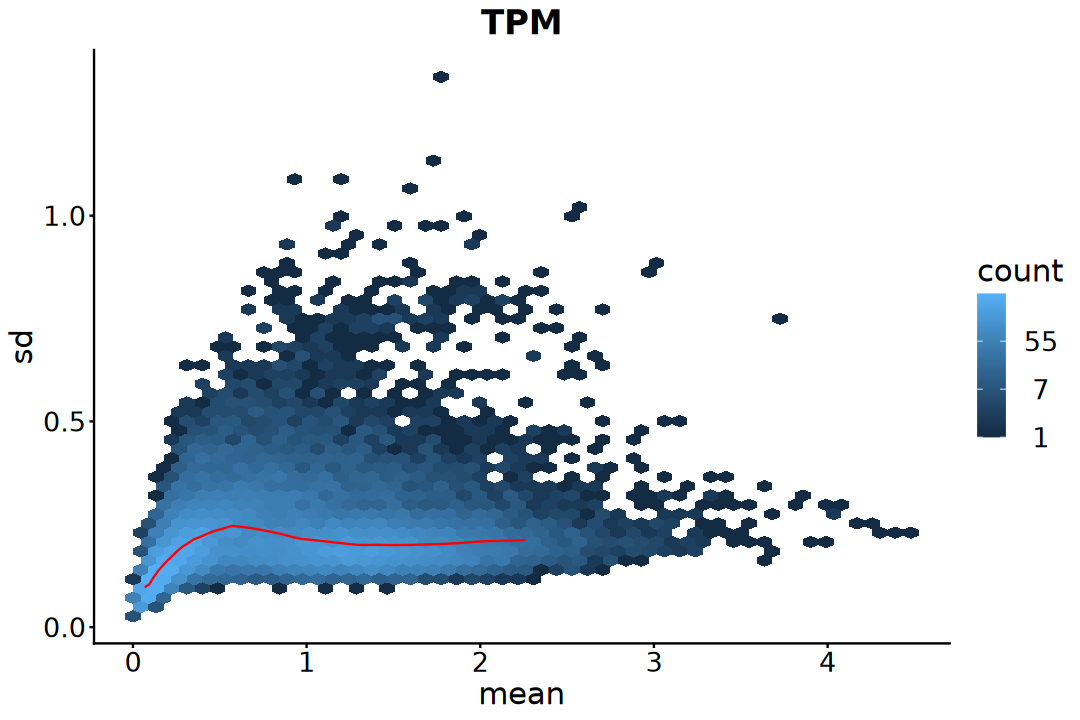

In [24]:
options(repr.plot.width = 9, repr.plot.height = 6)

vsn::meanSdPlot(
    log10(assay(eSet, "TPM") + 1), 
    ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "TPM") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [25]:
vsd <- vst(dds, blind = FALSE)

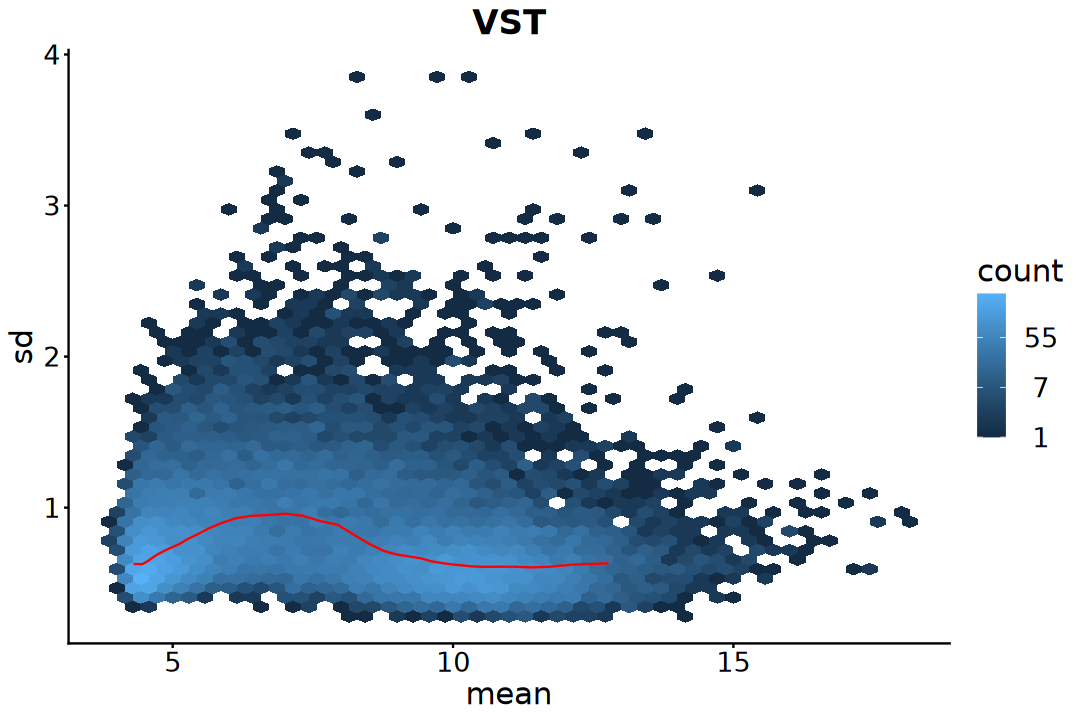

In [26]:
options(repr.plot.width = 9, repr.plot.height = 6)

vsn::meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 4. Exploration

In [27]:
norm_mat <- assay(vsd)

## 1). Overview

In [28]:
plot_df <- colData(dds) |> as.data.frame() |>
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(counts(dds))[Sample])

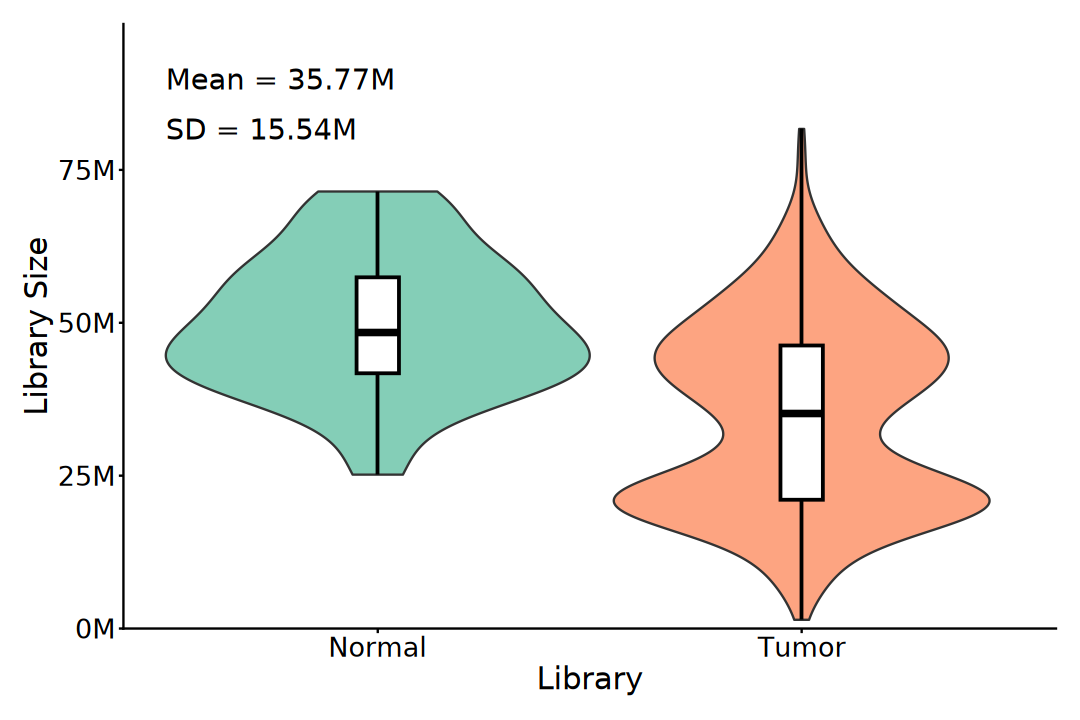

In [29]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize)) +
    geom_violin(
        aes(fill = Group), width = 1, alpha = 0.8,
        trim = TRUE, show.legend = FALSE) +
    geom_boxplot(
        color = "black", fill = "white", width = 0.1, 
        linewidth = 0.8, show.legend = FALSE) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"), 
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = "Library", y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

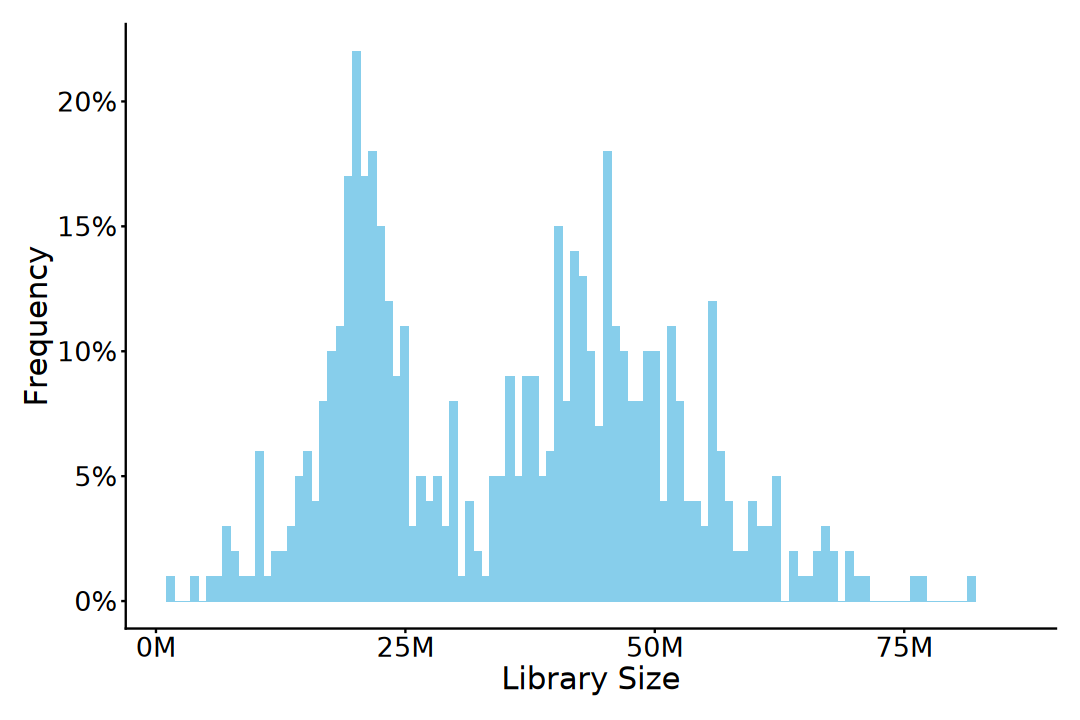

In [30]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = librarySize)) +
    geom_histogram(
        position = "identity", bins = 100, fill = "skyblue") +
    scale_x_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0.05, 0.1))) +
    scale_y_continuous(
        labels = scales::label_percent(scale = 1)) +
    labs(x = "Library Size", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). PCA

In [31]:
# CV can eliminate the bias that "high abundance tends to have large variance".
top_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> 
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)

In [32]:
pca_res <- norm_mat[top_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x[, 1:3], colData(dds), by = "row.names")

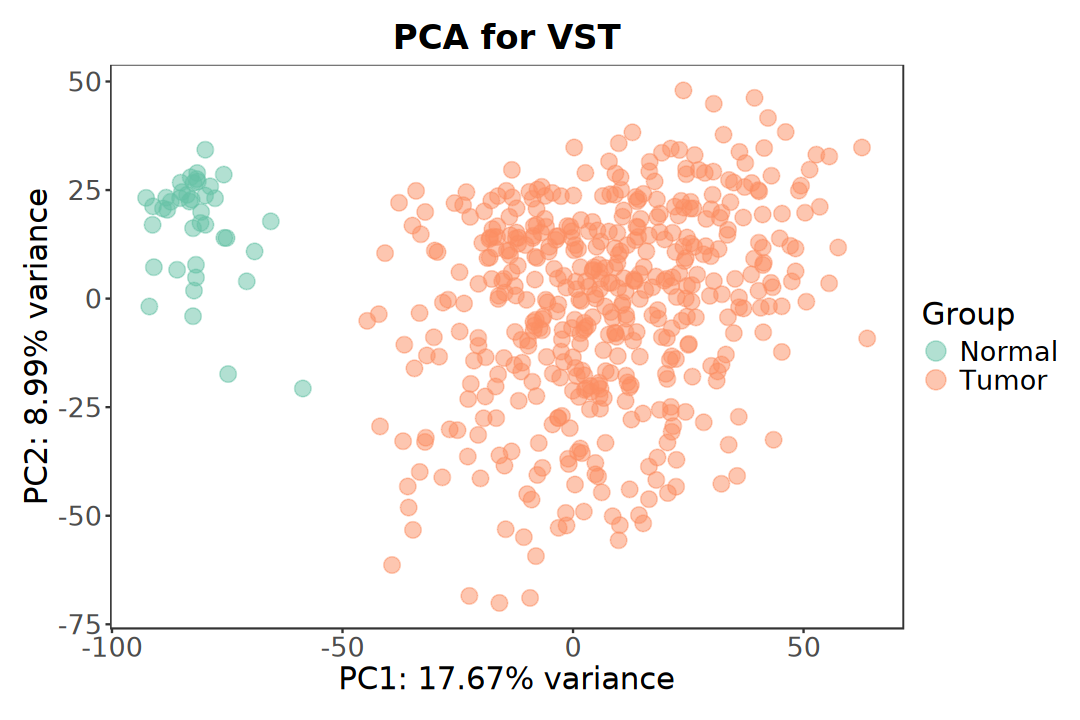

In [33]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pca_df, aes(PC1, PC2, color = Group)) +
    geom_point(size = 4, alpha = 0.5) +
    scale_color_brewer(palette = "Set2") +
    labs(
        title = "PCA for VST", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [34]:
plot_pca <- function(plot_df, group = NULL) {
    ggplot(plot_df, aes(PC1, PC2)) +
        geom_point(
            aes(color = !!sym(group)), size = 4, 
            alpha = 0.5, na.rm = TRUE) +
        scale_color_brewer(palette = "Set2") +
        labs(
            title = paste0("PCA for VST (", group, ")"), 
            x = paste0("PC1: ", per_var[1], "% variance"),
            y = paste0("PC2: ", per_var[2], "% variance")) +
        guides(
            color = guide_legend(override.aes = list(size = 5))) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

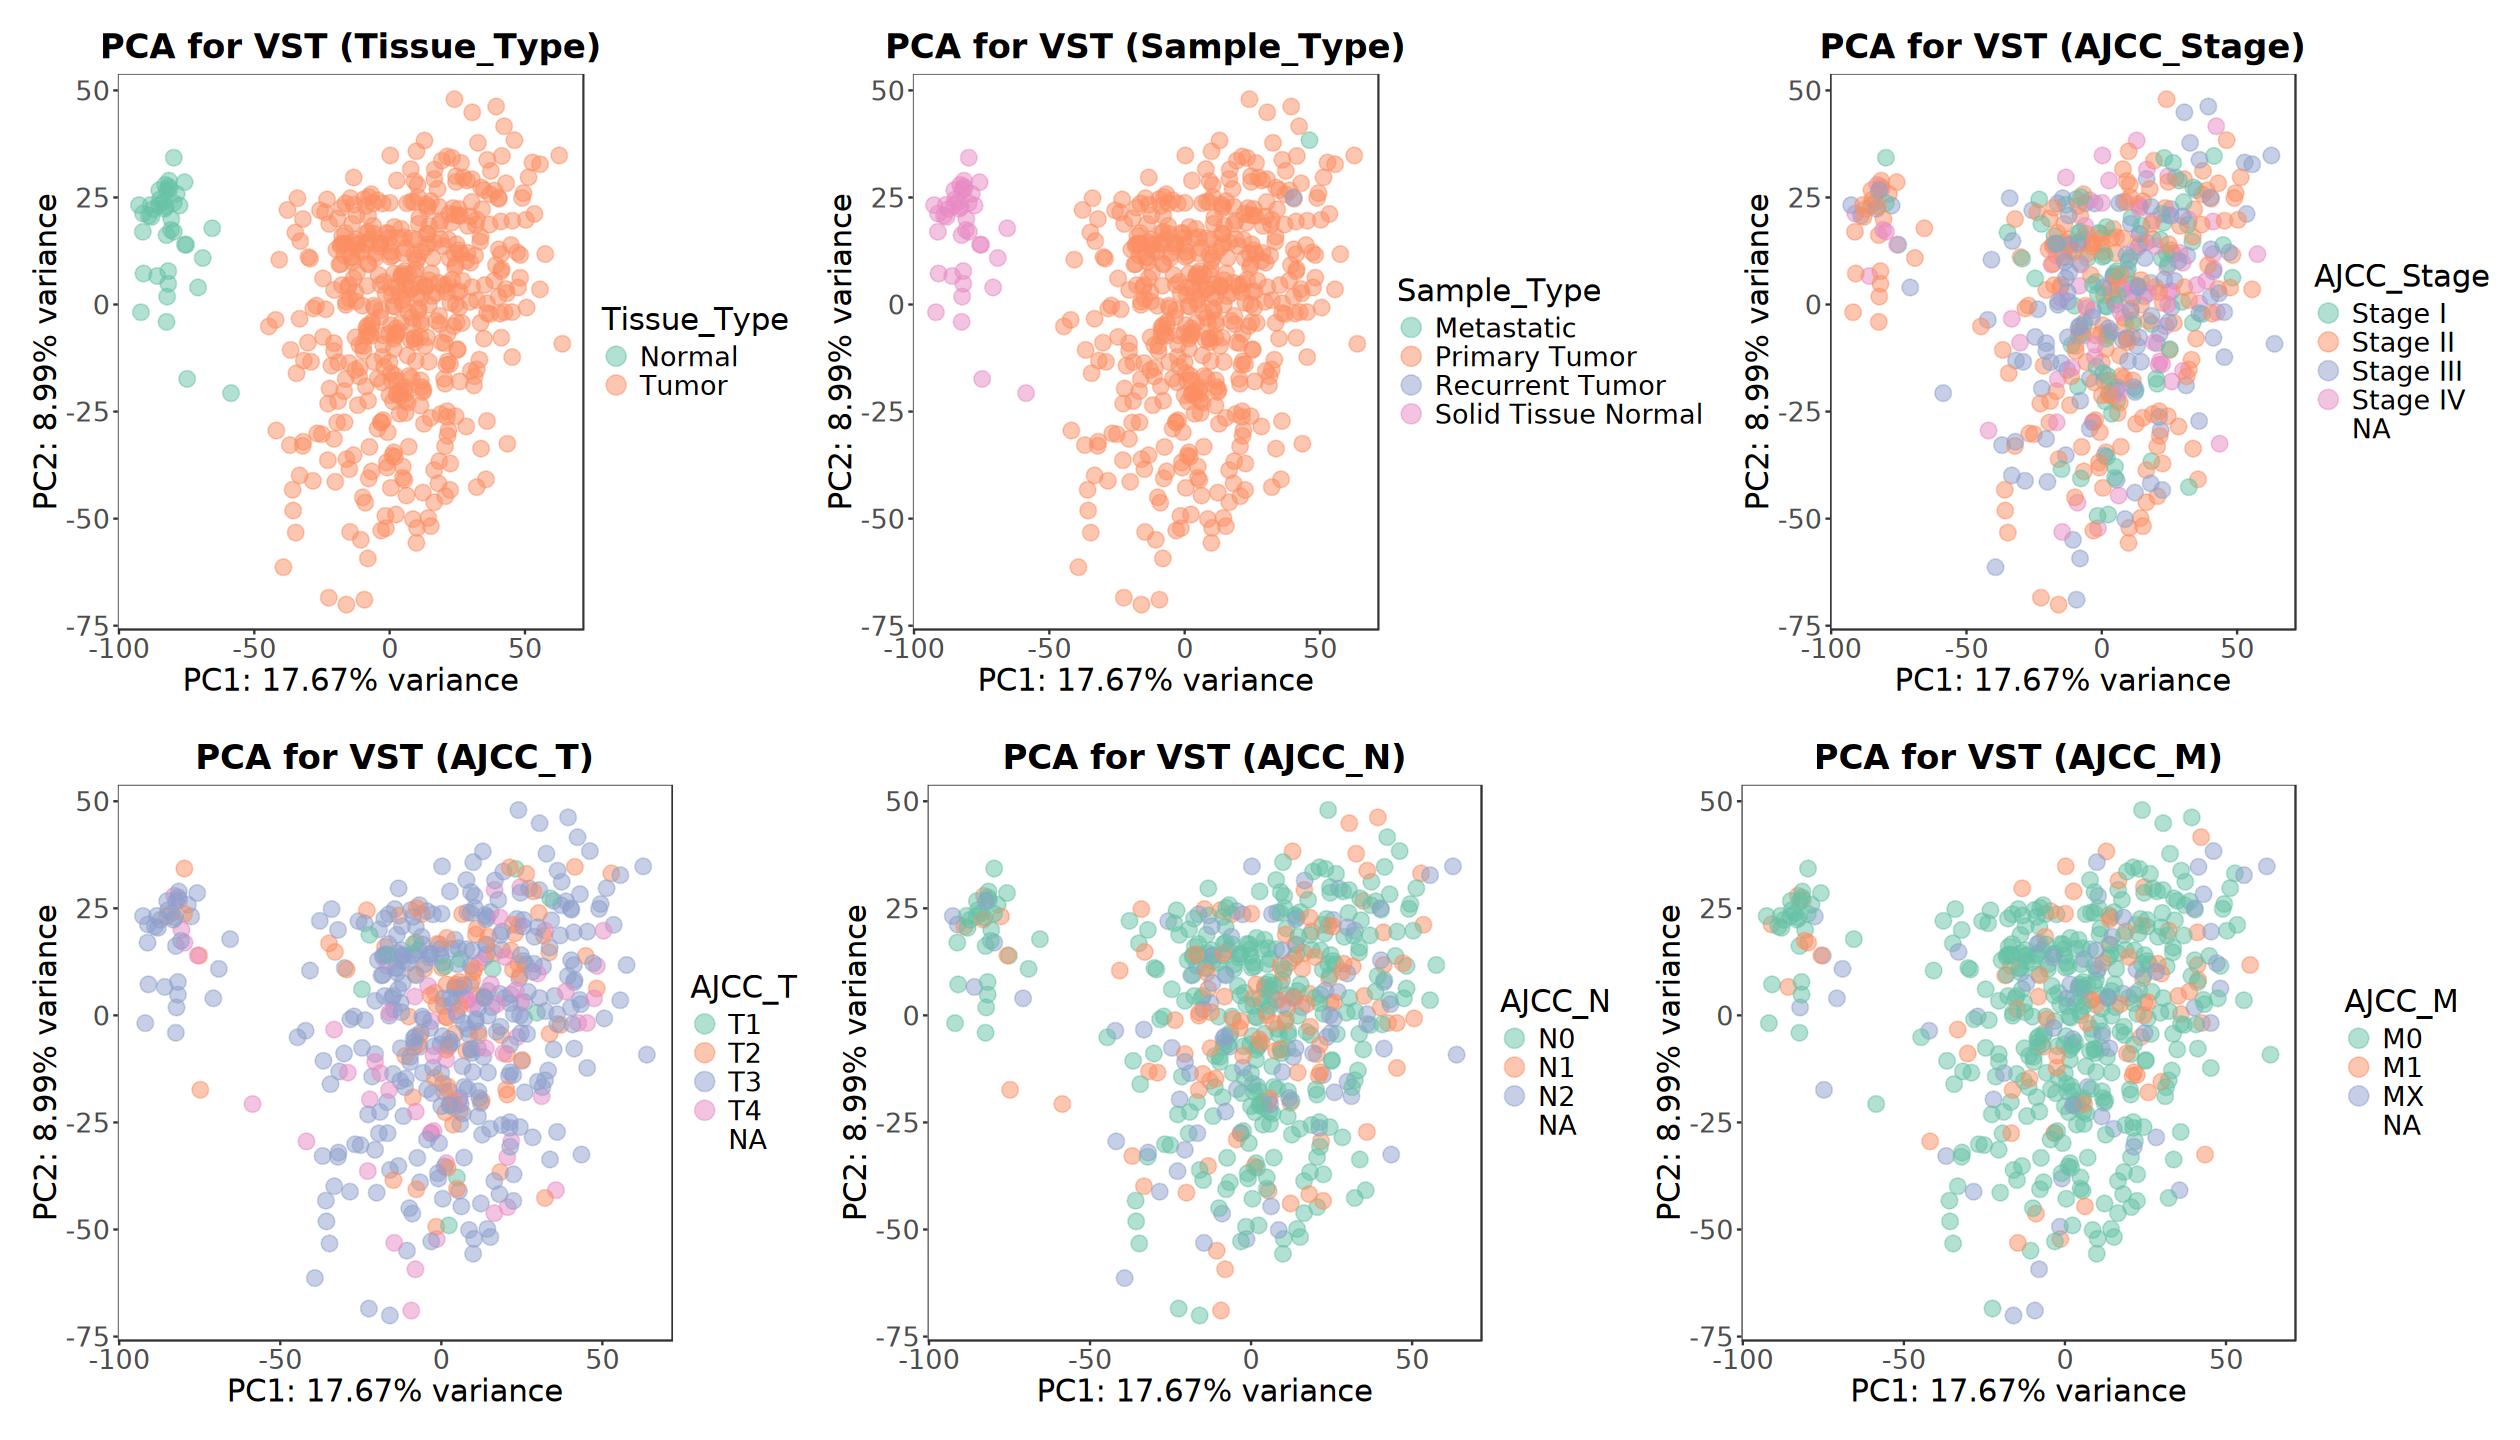

In [35]:
p1 <- plot_pca(pca_df, group = "Tissue_Type")
p2 <- plot_pca(pca_df, group = "Sample_Type")
p3 <- plot_pca(pca_df, group = "AJCC_Stage")
p4 <- plot_pca(pca_df, group = "AJCC_T")
p5 <- plot_pca(pca_df, group = "AJCC_N")
p6 <- plot_pca(pca_df, group = "AJCC_M")

options(repr.plot.width = 21, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + p5 + p6)

## 3). Heatmap

In [36]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(
        Gender, Tissue_Type, AJCC_Stage, AJCC_T, AJCC_N, AJCC_M)

In [37]:
sex_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(dds$Gender)),
    levels(dds$Gender))
stage_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$AJCC_Stage)),
    levels(dds$AJCC_Stage))
t_colors <- setNames(
    scales::brewer_pal(palette = "Reds")(nlevels(dds$AJCC_T)),
    levels(dds$AJCC_T))
n_colors <- setNames(
    scales::brewer_pal(palette = "Blues")(nlevels(dds$AJCC_N)),
    levels(dds$AJCC_N))
m_colors <- setNames(
    scales::brewer_pal(palette = "Greens")(nlevels(dds$AJCC_M)),
    levels(dds$AJCC_M))
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Tissue_Type)),
    levels(dds$Tissue_Type))

anno_colors <- list(
    Gender = sex_colors, AJCC_Stage = stage_colors, 
    AJCC_T = t_colors, AJCC_N = n_colors, AJCC_M = m_colors,
    Tissue_Type = group_colors)

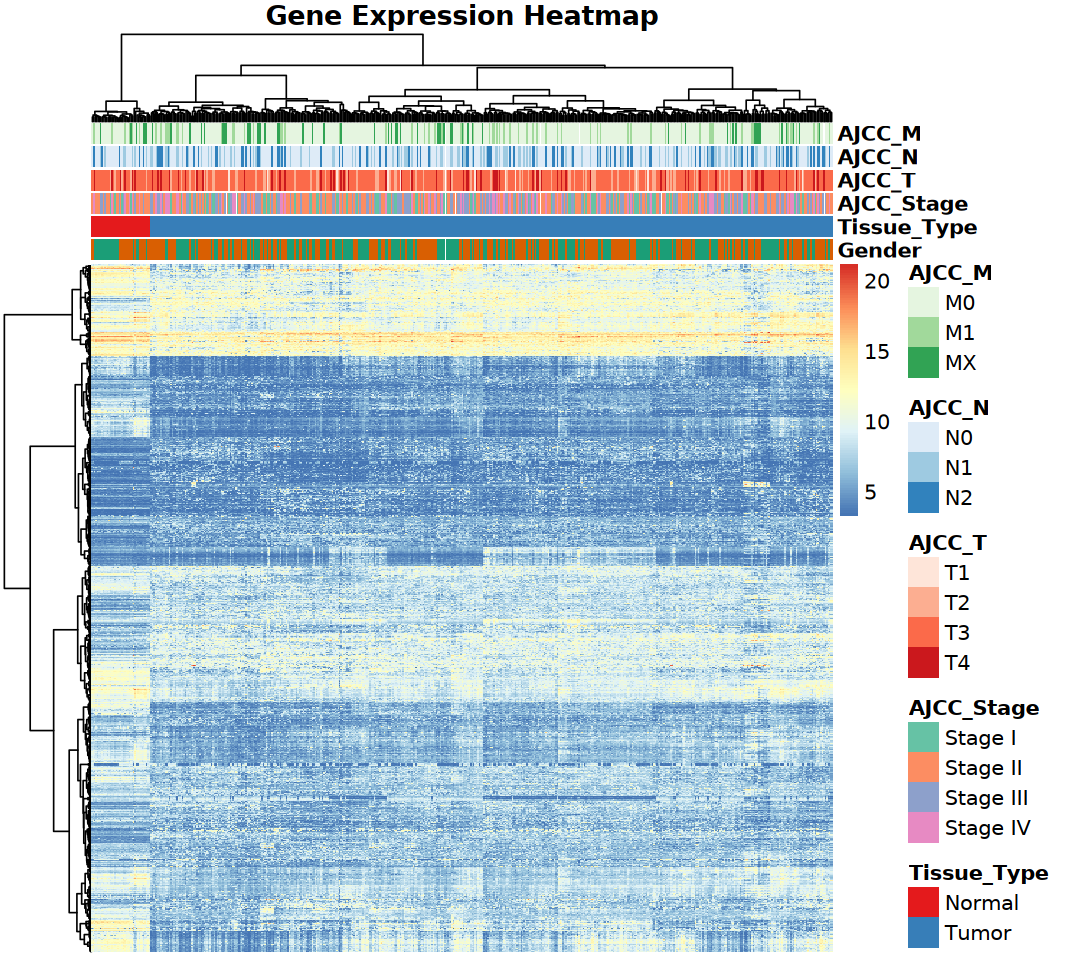

In [38]:
options(repr.plot.width = 9, repr.plot.height = 8)

mat_hc <- pheatmap::pheatmap(
    norm_mat[top_idx, ],
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    clustering_distance_rows = "euclidean",
    clustering_method = "ward.D2",
    main = "Gene Expression Heatmap", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

## 4). Cluster Tree

In [39]:
suppressPackageStartupMessages(library(ggdendro))
suppressPackageStartupMessages(library(ggnewscale))

In [40]:
tree_list <- ggdendro::dendro_data(mat_hc$tree_col)

In [41]:
tree_df <- tree_list$labels |> 
    left_join(
        ac |> rownames_to_column("sample"), 
        by = c("label" = "sample"))

head(tree_df)

,x,y,label,Gender,Tissue_Type,AJCC_Stage,AJCC_T,AJCC_N,AJCC_M
,<dbl>,<dbl>,<chr>,<fct>,<fct>,<ord>,<ord>,<ord>,<ord>
1,1,0,TCGA-AA-3655-11A,male,Normal,Stage II,T3,N0,M0
2,2,0,TCGA-A6-2671-11A,male,Normal,Stage IV,T3,N2,M1
3,3,0,TCGA-AA-3662-11A,female,Normal,Stage IV,T4,N2,M1
4,4,0,TCGA-AA-3531-11A,female,Normal,Stage II,T3,N0,M0
5,5,0,TCGA-AA-3660-11A,female,Normal,Stage II,T3,N0,M0
6,6,0,TCGA-A6-2685-11A,female,Normal,Stage II,T3,N0,M0


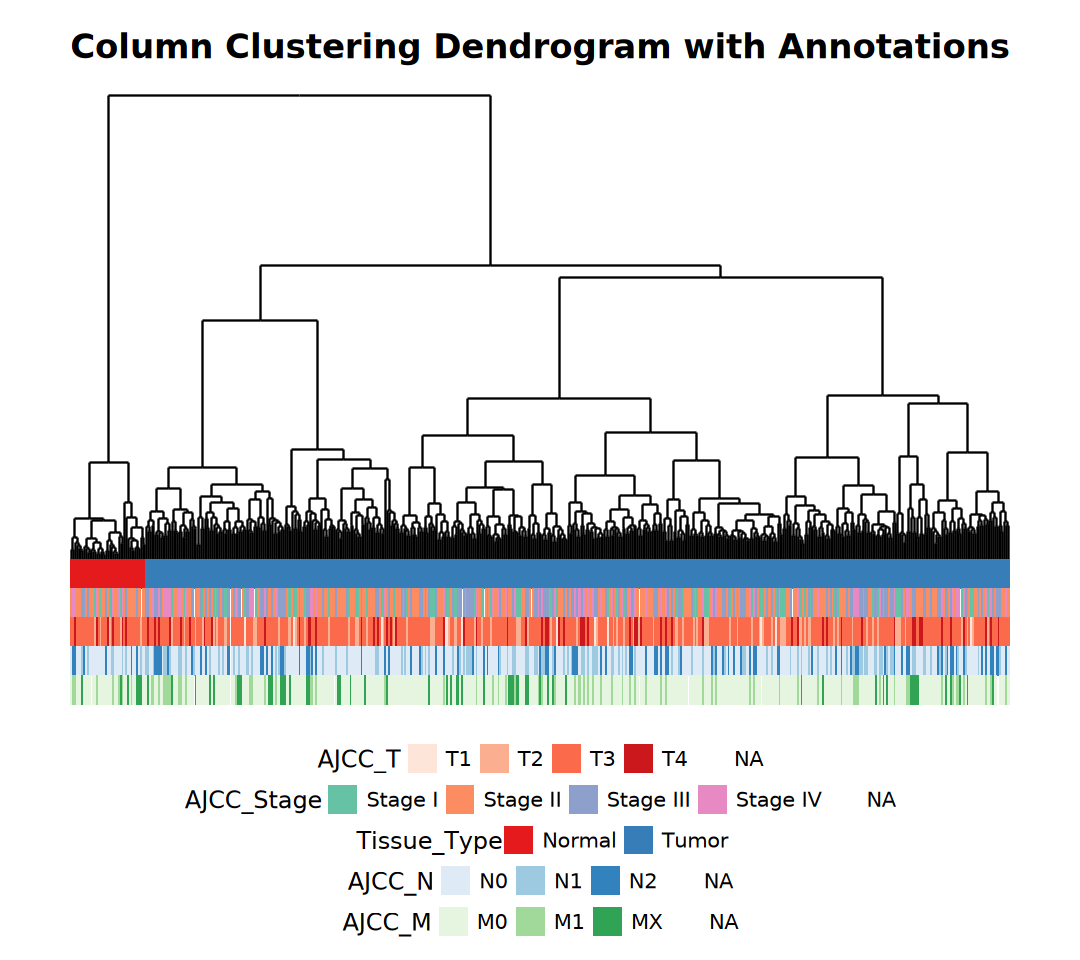

In [42]:
options(repr.plot.width = 9, repr.plot.height = 8)
ggplot() + 
    geom_segment(
        data = ggdendro::segment(tree_list), 
        aes(x = x, y = y, xend = xend, yend = yend)) +
    geom_tile(
        data = tree_df, 
        aes(x = x, y = 0, fill = Tissue_Type), height = 50) +
    scale_fill_brewer(name = "Tissue_Type", palette = "Set1") +
    ggnewscale::new_scale_fill() +
    geom_tile(
        data = tree_df, 
        aes(x = x, y = -50, fill = AJCC_Stage), height = 50) +
    scale_fill_brewer(name = "AJCC_Stage", palette = "Set2") +
    ggnewscale::new_scale_fill() +
    geom_tile(
        data = tree_df, 
        aes(x = x, y = -100, fill = AJCC_T), height = 50) +
    scale_fill_brewer(name = "AJCC_T", palette = "Reds") +
    ggnewscale::new_scale_fill() +
    geom_tile(
        data = tree_df, 
        aes(x = x, y = -150, fill = AJCC_N), height = 50) +
    scale_fill_brewer(name = "AJCC_N", palette = "Blues") +
    ggnewscale::new_scale_fill() +
    geom_tile(
        data = tree_df, 
        aes(x = x, y = -200, fill = AJCC_M), height = 50) +
    scale_fill_brewer(name = "AJCC_M", palette = "Greens") +
    ggnewscale::new_scale_fill() +
    labs(title = "Column Clustering Dendrogram with Annotations") +
    theme_void() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "bottom",
        legend.box = "vertical",
        legend.title = element_text(size = 14), 
        legend.text = element_text(size = 12),
        axis.title = element_blank(), 
        axis.text = element_blank(),
        axis.ticks = element_blank())

In [43]:
suppressPackageStartupMessages(library(ape))
suppressPackageStartupMessages(library(ggtree))
suppressPackageStartupMessages(library(ggtreeExtra))

In [44]:
mat_hc_clusters <- cutree(mat_hc$tree_col, k = 7)
table(mat_hc_clusters)

mat_hc_clusters
  1   2   3   4   5   6   7 
 62 118  63  76  92  41  62 

In [45]:
tree_df <- ape::as.phylo(mat_hc$tree_col)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ggtree package.
  Please report the issue at <https://github.com/YuLab-SMU/ggtree/issues>.”


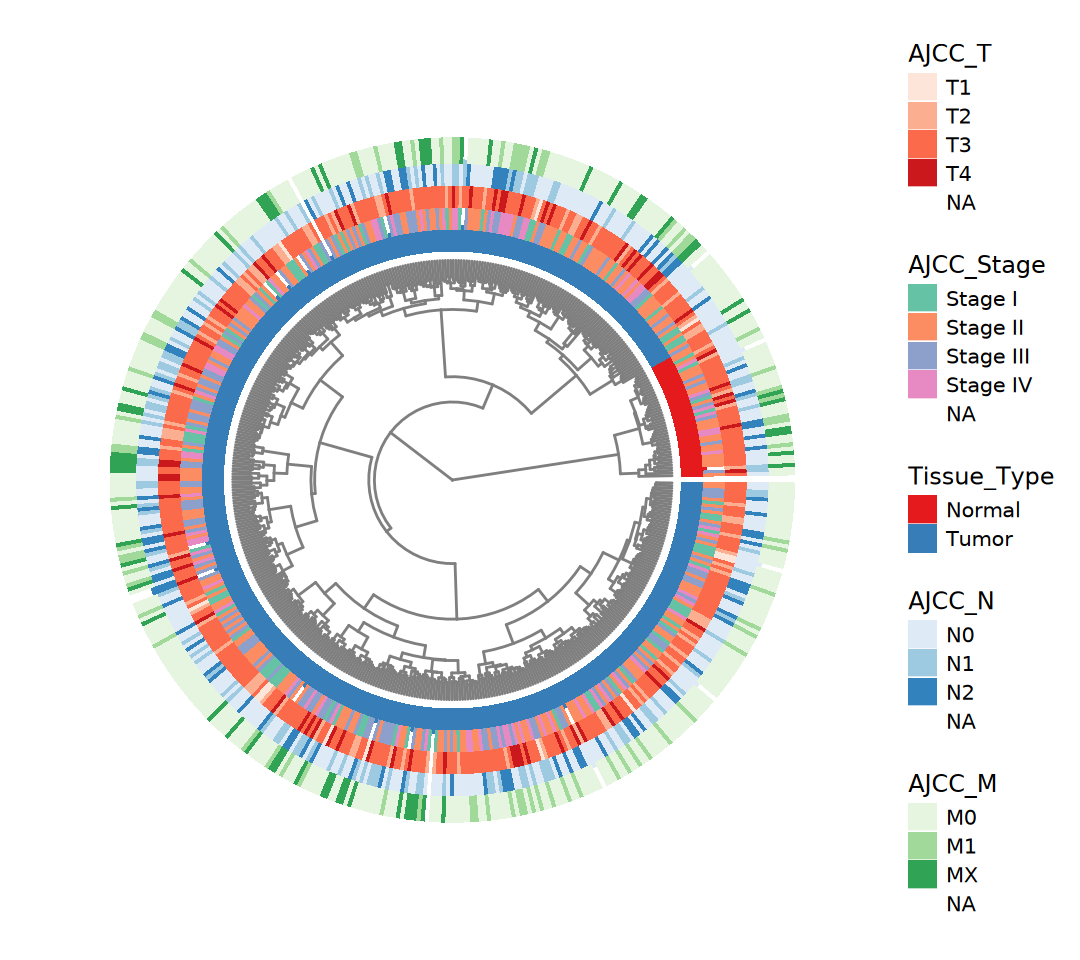

In [46]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggtree(tree_df, layout = "circular", size = 0.6, color = "gray50") +
    geom_fruit(
        data = rownames_to_column(ac, "sample"), 
        aes(y = sample, x = "Tissue_Type", fill = Tissue_Type),
        geom_tile, offset = 0.05, width = 50) +
    scale_fill_brewer(name = "Tissue_Type", palette = "Set1") +
    ggnewscale::new_scale_fill() +
    geom_fruit(
        data = rownames_to_column(ac, "sample"),
        aes(y = sample, x = "AJCC_Stage", fill = AJCC_Stage),
        geom = geom_tile, offset = 0.05, width = 50) +
    scale_fill_brewer(name = "AJCC_Stage", palette = "Set2") +
    ggnewscale::new_scale_fill() +
    geom_fruit(
        data = rownames_to_column(ac, "sample"),
        aes(y = sample, x = "AJCC_T", fill = AJCC_T),
        geom = geom_tile, offset = 0.05, width = 50) +
    scale_fill_brewer(name = "AJCC_T", palette = "Reds") +
    ggnewscale::new_scale_fill() +
    geom_fruit(
        data = rownames_to_column(ac, "sample"),
        aes(y = sample, x = "AJCC_N", fill = AJCC_N),
        geom = geom_tile, offset = 0.05, width = 50) +
    scale_fill_brewer(name = "AJCC_N", palette = "Blues") +
    ggnewscale::new_scale_fill() +
    geom_fruit(
        data = rownames_to_column(ac, "sample"),
        aes(y = sample, x = "AJCC_M", fill = AJCC_M),
        geom = geom_tile, offset = 0.05, width = 50) +
    scale_fill_brewer(name = "AJCC_M", palette = "Greens") +
    ggnewscale::new_scale_fill() +
    guides(fill = guide_legend(nrow = 5, override.aes = list(size = 1))) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.box = "vertical",
        legend.title = element_text(size = 14), 
        legend.text = element_text(size = 12))

## 5). Correlation

In [47]:
cor_mat <- cor(norm_mat[top_idx, ], method = "spearman")

In [48]:
colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

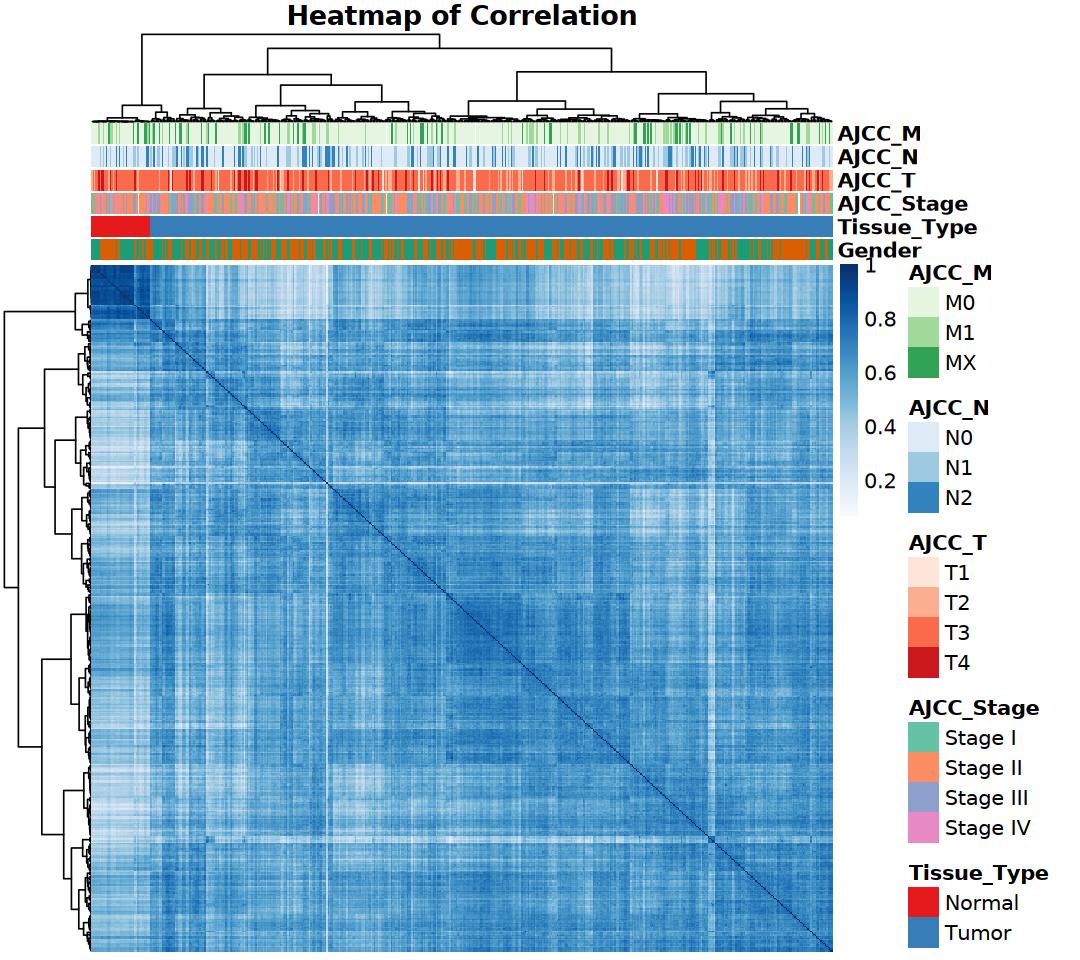

In [49]:
options(repr.plot.width = 9, repr.plot.height = 8)

cor_hc <- pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    clustering_method = "ward.D2",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 12,
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs Analysis

In [50]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

## 1). DESeq2

In [51]:
dds <- DESeq(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 1148 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



In [52]:
res <- results(
    dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, name = "Group_Tumor_vs_Normal", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Group", "Tumor", "Normal"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 21284 with nonzero total read count
adjusted p-value < 0.05
LFC > 2.00 (up)    : 711, 3.3%
LFC < -2.00 (down) : 412, 1.9%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [53]:
deseq2_result <- res |> as.data.frame() |> 
    dplyr::rename(logFC = log2FoldChange) |>
    rownames_to_column("gene_id") |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
            dplyr::select(gene_name, gene_type) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
  711   412 20161 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,gene_name,gene_type
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>
ENSG00000000003.15,5158.45031,0.43601971,0.14420275,3.0236574,1.0000000,1,NS,TSPAN6,protein_coding
ENSG00000000005.6,42.39499,0.41774506,0.30176385,1.3843443,0.9999999,1,NS,TNMD,protein_coding
ENSG00000000419.13,1730.47541,0.82975611,0.11298911,7.3436821,1.0000000,1,NS,DPM1,protein_coding
ENSG00000000457.14,460.67263,-0.28188072,0.06768682,-4.1644846,1.0000000,1,NS,SCYL3,protein_coding
ENSG00000000460.17,325.53491,1.25134264,0.09308131,13.4435429,1.0000000,1,NS,C1orf112,protein_coding
ENSG00000000938.13,253.74622,0.04533701,0.19242524,0.2356085,1.0000000,1,NS,FGR,protein_coding


In [54]:
res_lfc <- lfcShrink(
    dds, coef = "Group_Tumor_vs_Normal", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 21284 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 9688, 46%
LFC < 0 (down)     : 6948, 33%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 3)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [55]:
deseq2_result <- res_lfc |> as.data.frame() |> 
    dplyr::rename(logFC = log2FoldChange) |>
    rownames_to_column("gene_id") |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
            dplyr::select(gene_name, gene_type) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
 1257   898 19129 

,baseMean,logFC,lfcSE,pvalue,padj,result,gene_name,gene_type
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>
ENSG00000000003.15,5158.45031,0.43199072,0.14302290,2.497391e-03,3.934163e-03,NS,TSPAN6,protein_coding
ENSG00000000005.6,42.39499,0.37923874,0.29245826,1.662531e-01,2.010414e-01,NS,TNMD,protein_coding
ENSG00000000419.13,1730.47541,0.82391387,0.11292396,2.077964e-13,8.644914e-13,NS,DPM1,protein_coding
ENSG00000000457.14,460.67263,-0.27961230,0.06747183,3.120566e-05,6.155337e-05,NS,SCYL3,protein_coding
ENSG00000000460.17,325.53491,1.24470917,0.09321165,3.359585e-41,9.310600e-40,NS,C1orf112,protein_coding
ENSG00000000938.13,253.74622,0.04416278,0.18826411,8.137365e-01,8.368558e-01,NS,FGR,protein_coding


## 2). edgeR

In [56]:
design <- model.matrix(~ group, data = dgel$samples)

In [57]:
dgel <- estimateDisp(dgel, design)

In [58]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [59]:
edger_result <- topTags(qlf, n = Inf) |> as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_result$result)
head(edger_result)


   Up  Down    NS 
 2075  1210 21836 

,basepairs,gene_name,gene_type,logFC,logCPM,F,pvalue,padj,result
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000172689.2,2311,MS4A10,protein_coding,-7.646452,0.18691573,2220.708,7.052409e-270,1.771636e-265,Down
ENSG00000204933.3,935,CD177P1,unprocessed_pseudogene,-6.633640,-0.42776292,2135.661,9.371731e-266,1.177136e-261,Down
ENSG00000110887.8,3883,DAO,protein_coding,-5.797540,-0.87946637,2055.965,4.831102e-259,4.045404e-255,Down
ENSG00000144410.5,1245,CPO,protein_coding,-6.308744,-0.02917521,2128.143,9.935577e-257,6.239791e-253,Down
ENSG00000131482.10,4365,G6PC,protein_coding,-6.648471,-0.86277624,1645.108,7.000442e-220,3.517162e-216,Down
ENSG00000183034.13,3001,OTOP2,protein_coding,-8.399934,3.24136324,2225.633,2.411199e-218,1.009529e-214,Down


## 3). limma-voom

In [60]:
design <- model.matrix(~ group, data = dgel$samples)

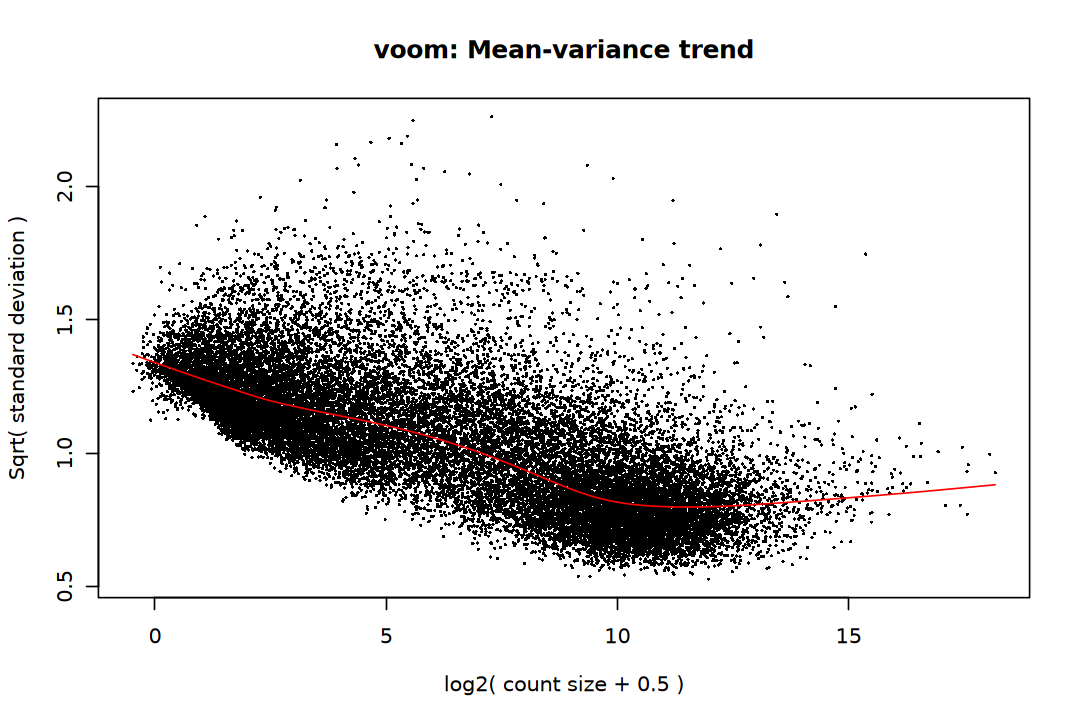

In [61]:
options(repr.plot.width = 9, repr.plot.height = 6)

v <- voom(dgel, design, plot = TRUE)

In [62]:
# Linear Model for Series of Arrays
fit <- lmFit(v, design)
# Empirical Bayes Statistics for Differential Expression
fit <- eBayes(fit)

In [63]:
limma_result <- topTable(fit, coef = 2, number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_result$result)
head(limma_result)


   Up  Down    NS 
  788  1808 22525 

,basepairs,gene_name,gene_type,logFC,AveExpr,t,pvalue,padj,B,result
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000183034.13,3001,OTOP2,protein_coding,-10.277279,-3.01340292,-53.94095,1.306690e-214,3.282537e-210,480.2853,Down
ENSG00000142959.5,2512,BEST4,protein_coding,-6.531276,0.34329197,-43.71963,6.722538e-176,8.443843e-172,391.8056,Down
ENSG00000168748.14,1827,CA7,protein_coding,-7.186082,-0.06597084,-42.81129,3.362612e-172,2.815739e-168,383.3115,Down
ENSG00000182938.7,2337,OTOP3,protein_coding,-6.446406,-4.79411427,-39.29713,1.806749e-157,1.134684e-153,348.5544,Down
ENSG00000167916.5,1883,KRT24,protein_coding,-6.802674,-4.78523905,-37.94834,1.227020e-151,6.164795e-148,335.3768,Down
ENSG00000163815.6,985,CLEC3B,protein_coding,-4.420712,0.33267766,-35.62957,2.213686e-141,9.268336e-138,312.5724,Down


## 4). Wilcoxon-test

In [64]:
# edgeR TMM
norm_mat <- cpm(
    dgel, normalized.lib.sizes = TRUE, 
    log = TRUE, prior.count = 1)

# # voom
# design <- model.matrix(~ group, data = dgel$samples)
# norm_mat <- voom(dgel, design, plot = FALSE)

# # DESeq2 normalization
# norm_mat <- counts(dds, normalized = TRUE)
# norm_mat <- log2(norm_mat + 1)

# # log2(CPM + 1)
# expr_mat <- assay(eSet, "counts")
# norm_mat <- sweep(expr_mat, 2, colSums(expr_mat), FUN = "/") * 1e6  
# norm_mat <- log2(norm_mat + 1)

In [65]:
# =============================================================================
# Wilcoxon-test based Differential Expression Analysis
# =============================================================================
# Cliff's Delta: effect size, range [-1, 1]
#   Formula: delta = (2U)/(m*n) - 1  (equivalent to (U1 - U2) / (m*n))
#   Note: wilcox.test W statistic = U1 (treat vs control)
#         so U = W - m*(m+1)/2 gives U2 (control vs treat)
#         correct formula should use U1: delta = (2*W_U1)/(m*n) - 1
# =============================================================================

wilcoxDEG <- function(mat, group, adjust_method = "BH") {
    idx_c <- which(group == levels(group)[1])
    num_c <- length(idx_c)
    idx_t <- which(group == levels(group)[2])
    num_t <- length(idx_t)
    
    result <- apply(mat, 1, function(x) {
        wt <- wilcox.test(
            x[idx_t], x[idx_c], exact = FALSE, correct = FALSE)
        W <- wt$statistic |> as.numeric()
        c(
            logFC = mean(x[idx_t]) - mean(x[idx_c]),
            W = W,
            cliffs_delta = (2 * W) / (num_t * num_c) - 1,
            pvalue = wt$p.value)
    }) |> t() |> as.data.frame()
    
    result$padj <- p.adjust(result$pvalue, method = adjust_method)
    return(result)
}

In [66]:
res <- wilcoxDEG(norm_mat, group = colData(eSet)$Group)

In [67]:
wilcox_result <- res |> 
    rownames_to_column("gene_id") |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
            dplyr::select(gene_name, gene_type) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(wilcox_result$result)
head(wilcox_result)


   Up  Down    NS 
  551  1731 22839 

,logFC,W,cliffs_delta,pvalue,padj,result,gene_name,gene_type
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>
ENSG00000000003.15,0.2042252,11805,0.2174496,2.082164e-02,2.854354e-02,NS,TSPAN6,protein_coding
ENSG00000000005.6,-0.7757668,7654,-0.2106430,2.516023e-02,3.406176e-02,NS,TNMD,protein_coding
ENSG00000000419.13,0.6797805,15645,0.6134688,7.013603e-11,2.479436e-10,NS,DPM1,protein_coding
ENSG00000000457.14,-0.3215435,4821,-0.5028103,9.081128e-08,2.312958e-07,NS,SCYL3,protein_coding
ENSG00000000460.17,1.1948308,18416,0.8992420,1.203336e-21,2.566130e-20,NS,C1orf112,protein_coding
ENSG00000000938.13,-0.3955807,7937,-0.1814572,5.377413e-02,6.930330e-02,NS,FGR,protein_coding


# 6. DEGs Visualization

## 1). Volcano

In [68]:
add_label <- function(res, symbol_col = "symbol"){
    res |>
        tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 10,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [69]:
deseq2_result <- add_label(deseq2_result, symbol_col = "gene_name")
edger_result <- add_label(edger_result, symbol_col = "gene_name")
limma_result <- add_label(limma_result, symbol_col = "gene_name")
wilcox_result <- add_label(wilcox_result, symbol_col = "gene_name")

In [70]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 10) * 10)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), 
            na.rm = TRUE, alpha = 1) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(color = result, label = label), na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [71]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")
p4 <- ggplot_volcano(wilcox_result, title = "Wilcoxon-test")

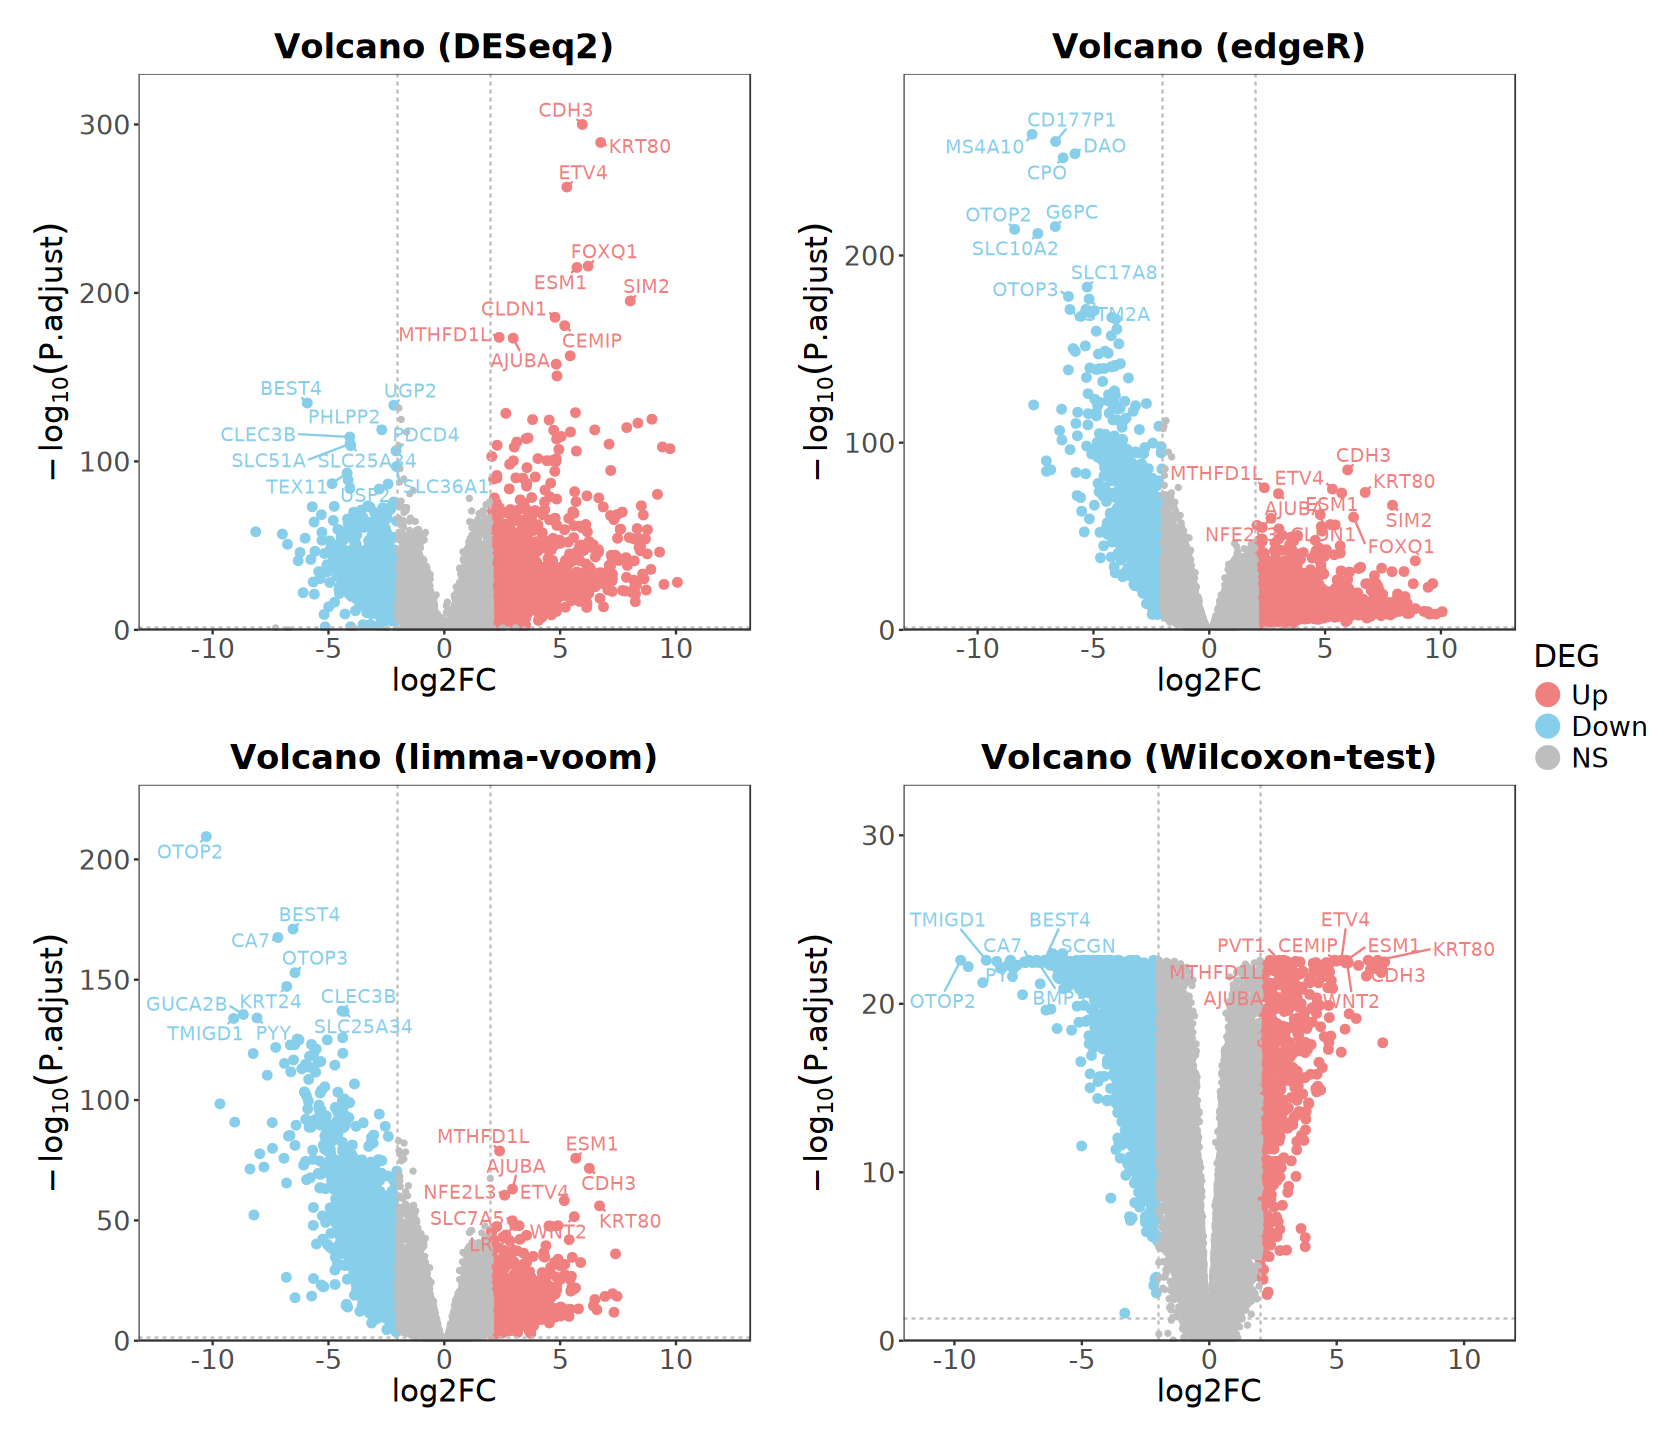

In [72]:
options(repr.plot.width = 14, repr.plot.height = 12)
p1 + p2 + p3 + p4 + plot_layout(nrow = 2, guides = "collect")

## 2). Heatmap

In [98]:
ar <- deseq2_result |> 
    filter(result %in% c("Up", "Down")) |> 
    select(DEG = result, logFC)

In [99]:
result_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- anno_colors |> 
    append(list(
        DEG = result_colors, 
        logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev()))

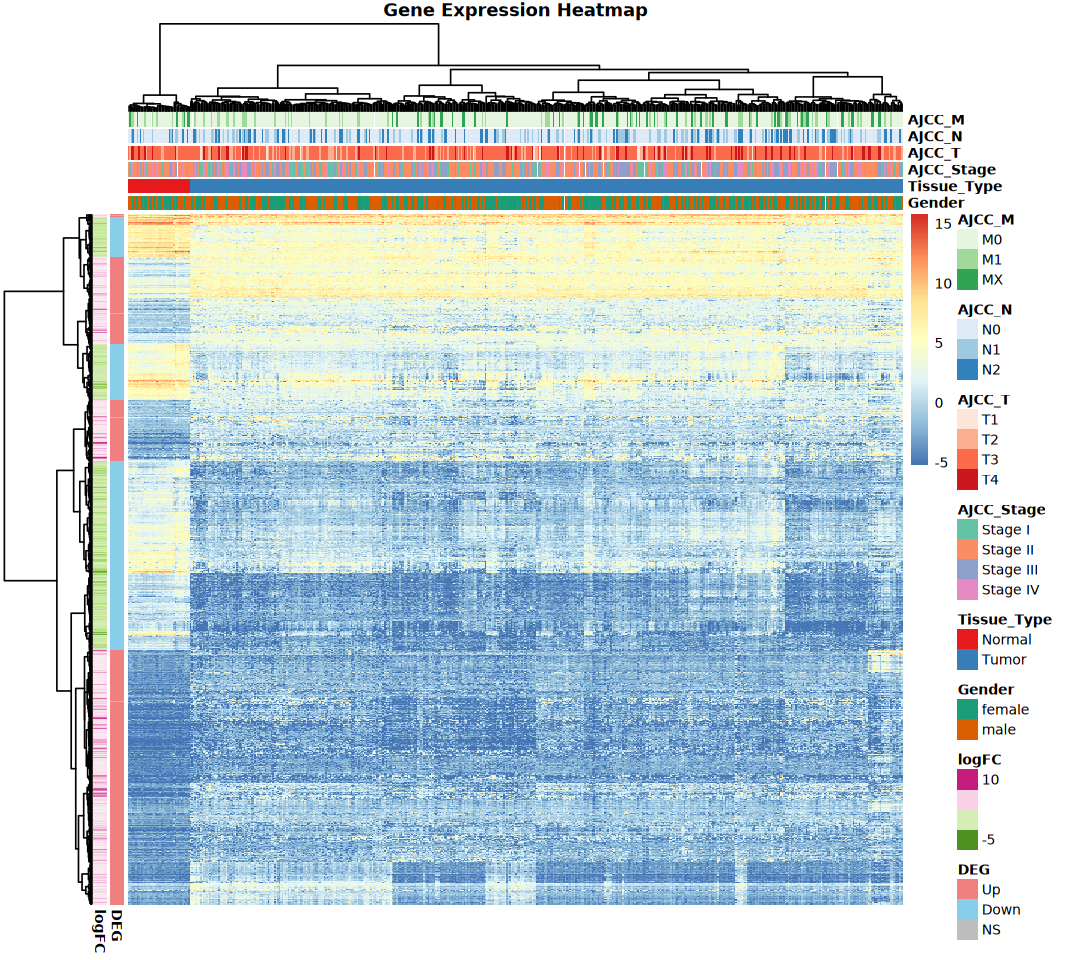

In [103]:
options(repr.plot.width = 9, repr.plot.height = 8)

mat_hc <- pheatmap::pheatmap(
    norm_mat[rownames(ar), ],
    annotation_col = ac, annotation_row = ar, 
    annotation_colors = anno_colors, 
    clustering_distance_rows = "euclidean",
    clustering_method = "ward.D2",
    main = "Gene Expression Heatmap", fontsize = 8, 
    show_colnames = FALSE, show_rownames = FALSE)

## 3). Venn

In [76]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [77]:
genes_up <- list(
    DESeq2 = rownames(deseq2_result)[deseq2_result$result == "Up"], 
    edgeR = rownames(edger_result)[edger_result$result == "Up"], 
    limma = rownames(limma_result)[limma_result$result == "Up"],
    Wilcox = rownames(wilcox_result)[wilcox_result$result == "Up"])
genes_up <- lapply(genes_up, unique)

In [78]:
genes_down <- list(
    DESeq2 = rownames(deseq2_result)[deseq2_result$result == "Down"], 
    edgeR = rownames(edger_result)[edger_result$result == "Down"], 
    limma = rownames(limma_result)[limma_result$result == "Down"],
    Wilcox = rownames(wilcox_result)[wilcox_result$result == "Down"])
genes_down <- lapply(genes_down, unique)

In [79]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16))

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16))

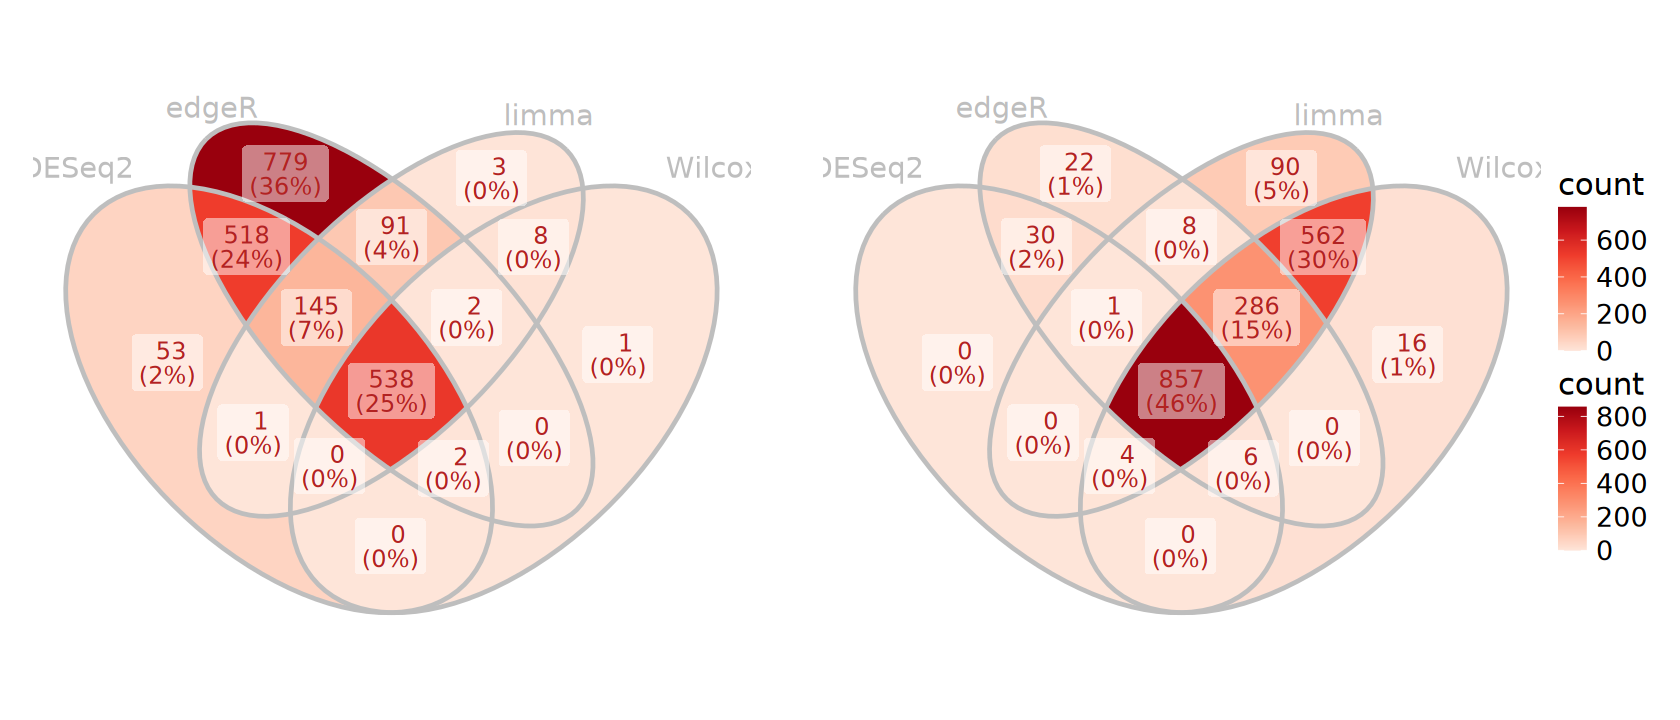

In [80]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 + 
    plot_layout(ncol = 3, widths = c(1, 0.01, 1), guides = "collect")

## 4). Upset

In [81]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors.”


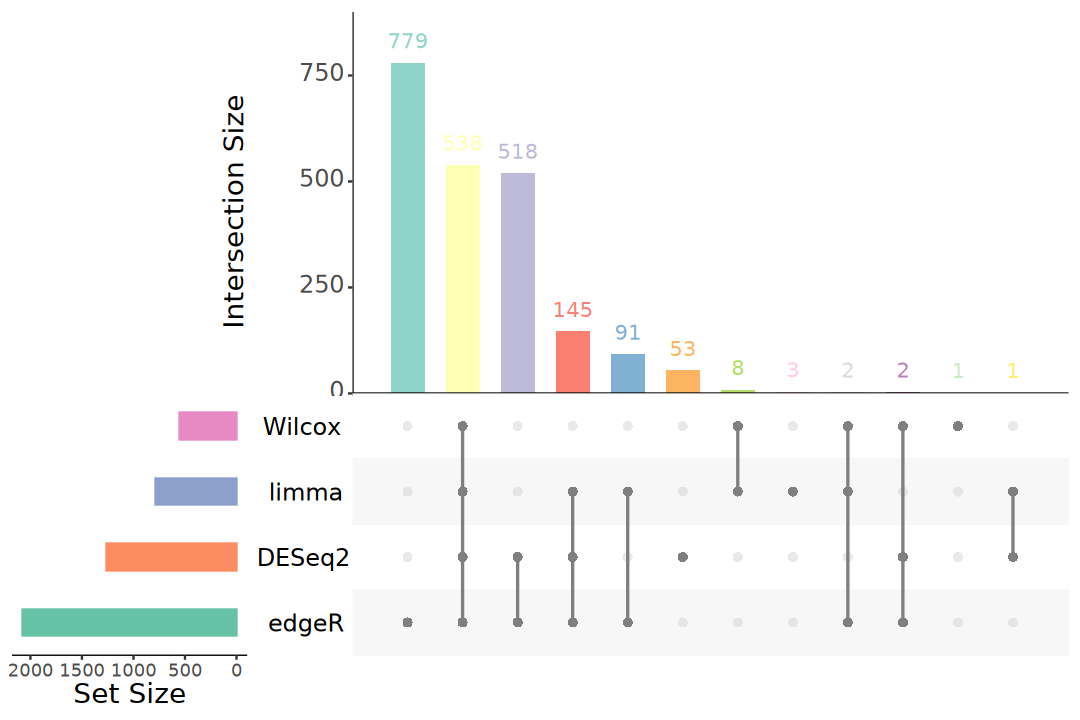

In [82]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 4, name = "Set2"),
    main.bar.color = brewer.pal(n = 12, name = "Set3"),
    matrix.color = "grey50",
    text.scale = c(2, 2, 2, 1.5, 2, 2))

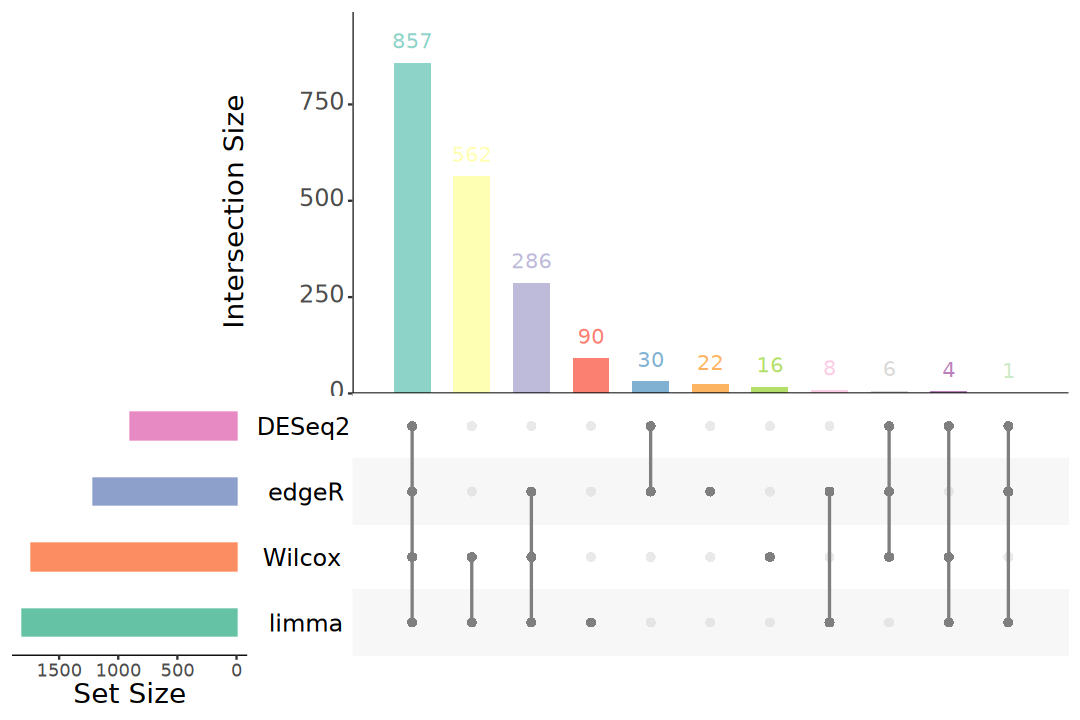

In [83]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 4, name = "Set2"),
    main.bar.color = brewer.pal(n = 11, name = "Set3"),
    matrix.color = "grey50",
    text.scale = c(2, 2, 2, 1.5, 2, 2))

# 7. Function Analysis

## 1). ORA

In [84]:
suppressPackageStartupMessages(library(org.Hs.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [ ]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [86]:
deseq2_result <- add_ENTREZID(
    deseq2_result, org.Hs.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
edger_result <- add_ENTREZID(
    edger_result, org.Hs.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
limma_result <- add_ENTREZID(
    limma_result, org.Hs.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
wilcox_result <- add_ENTREZID(
    wilcox_result, org.Hs.eg.db, fromType = "ENSEMBL",
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“15.18% of input gene IDs are fail to map...”
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“20.41% of input gene IDs are fail to map...”
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“20.41% of input gene IDs are fail to map...”
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“20.41% of input gene IDs are fail to map...”


In [ ]:
extract_gene_lists <- function(
    results_map, gene_col = "SYMBOL", result_col = "result", 
    directions = c("Up", "Down")) {
        
    lapply(names(results_map), function(method) {
        lapply(directions, function(dir) {
            df <- results_map[[method]]
            df[[gene_col]][df[[result_col]] == dir]
        })
    }) |>
    unlist(recursive = FALSE) |>
    setNames(
        nm = as.vector(t(outer(
            names(results_map), directions, paste, sep = "-"))))
}

In [88]:
results_map <- list(
    DESeq2 = deseq2_result, edgeR  = edger_result,
    limma  = limma_result, Wilcox = wilcox_result)

genes_list <- extract_gene_lists(
    results_map, gene_col = "gene_name", result_col = "result")

In [89]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(c(deseq2_result$SYMBOL, edger_result$SYMBOL)), 
    OrgDb = org.Hs.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [90]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,BP,GO:0043588,skin development,45/629,269/15298,0.1672862,4.068593,10.514257,6.210217e-16,2.633132e-12,2.383416e-12,45
2,DESeq2-Up,BP,GO:0008544,epidermis development,49/629,330/15298,0.1484848,3.611321,9.930329,4.106875e-15,8.706575e-12,7.880877e-12,49
3,DESeq2-Up,BP,GO:0031424,keratinization,16/629,38/15298,0.4210526,10.240482,11.809659,5.295024e-13,7.483634e-10,6.773915e-10,16
4,DESeq2-Up,BP,GO:0030216,keratinocyte differentiation,27/629,132/15298,0.2045455,4.974780,9.497137,3.566246e-12,3.780221e-09,3.421719e-09,27
5,DESeq2-Up,BP,GO:0009913,epidermal cell differentiation,32/629,200/15298,0.1600000,3.891383,8.522934,3.653249e-11,3.097955e-08,2.804157e-08,32
6,DESeq2-Up,BP,GO:0019730,antimicrobial humoral response,26/629,147/15298,0.1768707,4.301699,8.329208,2.706988e-10,1.912938e-07,1.731522e-07,26


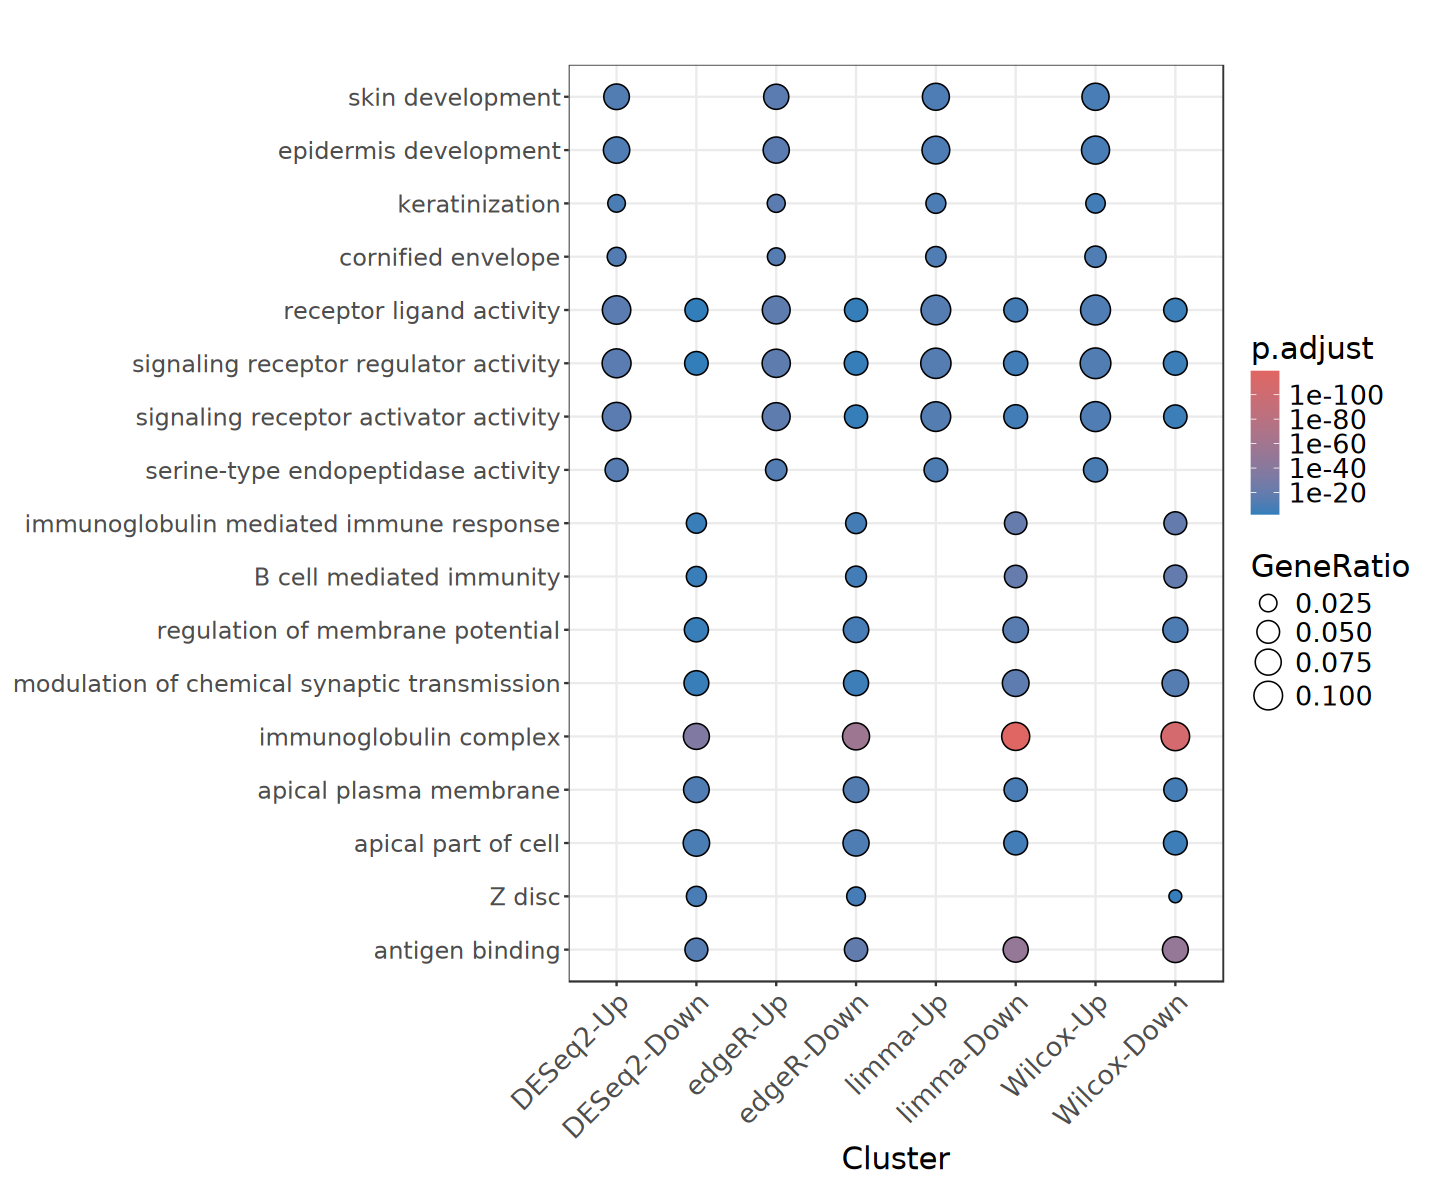

In [91]:
options(repr.plot.width = 12, repr.plot.height = 10)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [92]:
genes_list <- extract_gene_lists(
    results_map, gene_col = "ENTREZID", result_col = "result")

In [94]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(c(deseq2_result$ENTREZID, edger_result$ENTREZID)), 
    organism = "hsa", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [96]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,Organismal Systems,Development and regeneration,hsa04382,Cornified envelope formation,34/338,156/7412,0.2179487,4.779396,10.427983,8.396188e-15,2.468479e-12,2.377447e-12,34
2,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,hsa04060,Cytokine-cytokine receptor interaction,31/338,249/7412,0.1244980,2.730116,6.070040,2.700864e-07,3.853508e-05,3.711399e-05,31
3,DESeq2-Up,Organismal Systems,Immune system,hsa04657,IL-17 signaling pathway,17/338,89/7412,0.1910112,4.188684,6.614945,4.023863e-07,3.853508e-05,3.711399e-05,17
4,DESeq2-Up,Environmental Information Processing,Signal transduction,hsa04310,Wnt signaling pathway,24/338,168/7412,0.1428571,3.132713,6.111702,5.242869e-07,3.853508e-05,3.711399e-05,24
5,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,hsa04080,Neuroactive ligand-receptor interaction,29/338,267/7412,0.1086142,2.381801,5.026483,1.069261e-05,6.287256e-04,6.055395e-04,29
6,DESeq2-Up,Human Diseases,Immune disease,hsa05323,Rheumatoid arthritis,14/338,86/7412,0.1627907,3.569836,5.239447,2.942365e-05,1.243378e-03,1.197525e-03,14


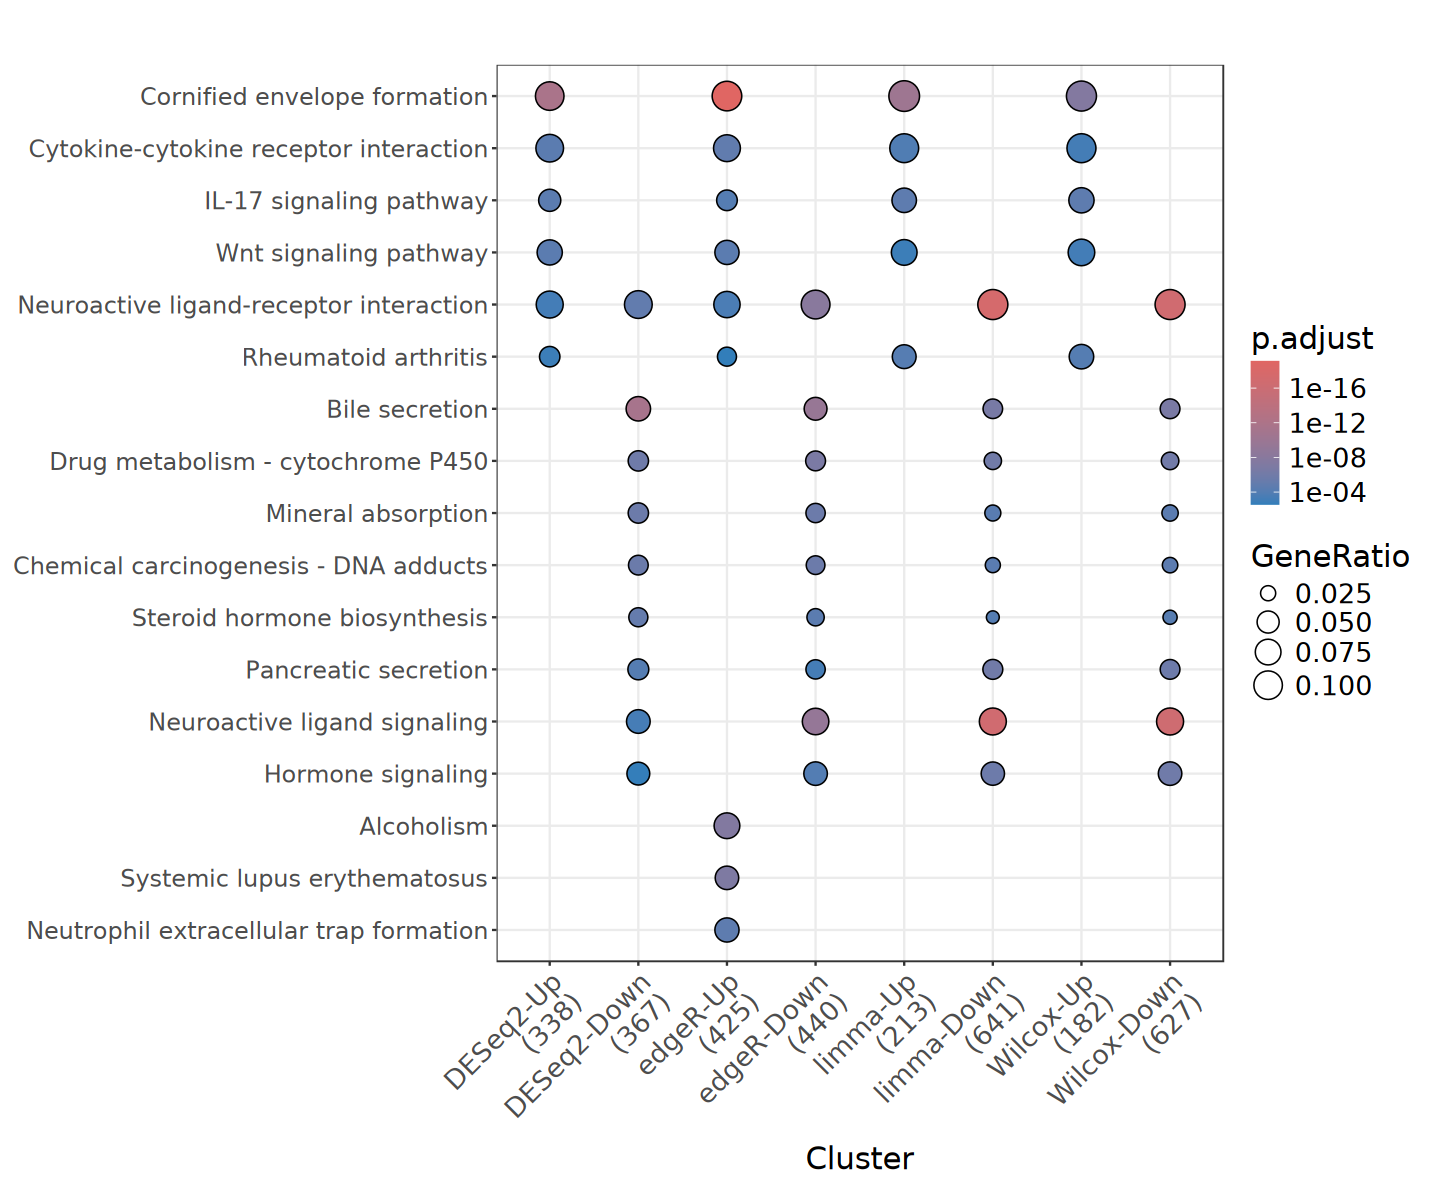

In [97]:
options(repr.plot.width = 12, repr.plot.height = 10)

dotplot(ekegg_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

## 3). GSVA